# Varunayan quickstart

Varunayan = Varun + ayan. In Vedic mythology, Varun is the god of the sky, order, truth and water. In Sanskrit, ayan means path.

Varunayan downloads climate variables for any region of the globe from [ERA5](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels). ERA5 is a reanalysis: it combines models and historical observations to estimate many atmospheric, land and ocean variables from 1940 to the present. Varunayan gets the data from the [Copernicus Climate Data Store](https://cds.climate.copernicus.eu/) (CDS), so you need a CDS API key in `~/.cdsapirc`.

In [1]:
import varunayan as v

✓ CDS API configuration is already set up and valid.


## Key arguments

The three download functions share these arguments.

| Argument | Meaning |
|---|---|
| `request_id` | Name of the request. Use a unique name for each request. |
| `variables` | ERA5 variable names, for example `"2m_temperature"`. |
| `start_date`, `end_date` | Dates as `"YYYY-MM-DD"`. |
| `frequency` | `"hourly"` (default), `"daily"`, `"weekly"`, `"monthly"` or `"yearly"`. |
| `resolution` | Grid size in degrees (default 0.25). |
| `dataset_type`, `pressure_levels` | Use `"pressure"` and a list such as `["850"]` for pressure-level data. |

## Data for a bounding box

`era5ify_bbox` gets the grid cells inside a box. Here we get daily temperature and precipitation for five days in a small box around Delhi.

The output is in long format: one row for each time, grid cell and variable. The `variable` column holds the ERA5 short name (`t2m` is 2 m temperature, `tp` is total precipitation). Temperatures are in °C. Precipitation is in mm and is the total for each day.

In [2]:
bbox = v.era5ify_bbox(
    request_id="quickstart_bbox",
    variables=["2m_temperature", "total_precipitation"],
    start_date="2024-01-01",
    end_date="2024-01-05",
    north=29,
    south=28,
    east=78,
    west=76.5,
    frequency="daily",
)
bbox.head()

/Users/mcclintock/github/varunayan/python/varunayan/core.py:291: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  merged_ds: xr.Dataset = xr.merge(datasets) if len(datasets) > 1 else datasets[0]
/Users/mcclintock/github/varunayan/python/varunayan/core.py:291: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  merged_ds: xr.Dataset = xr.merge(

,datetime,latitude,longitude,variable,value
0,2024-01-01,28.0,76.50,t2m,9.432020
1,2024-01-01,28.0,76.50,tp,0.030518
2,2024-01-01,28.0,76.75,t2m,9.737521
3,2024-01-01,28.0,76.75,tp,0.019550
4,2024-01-01,28.0,77.00,t2m,9.917453


## Data for a GeoJSON region

`era5ify_geojson` takes a path or URL of a GeoJSON file. Here we use the [LGD state boundaries of India](https://geo.bharatviz.org/geojsons/admin/India-geodata-lgd-states.geojson). With `level="feature"`, the output has one row for each state, with the mean of the grid cells inside it. The default `level="union"` keeps each grid cell.

In [3]:
states = v.era5ify_geojson(
    request_id="quickstart_states",
    variables=["2m_temperature"],
    start_date="2024-01-01",
    end_date="2024-01-01",
    json_file="https://geo.bharatviz.org/geojsons/admin/India-geodata-lgd-states.geojson",
    frequency="daily",
    level="feature",
)
states.head()

Found 3 invalid geometries. Attempting repair...


,state_name,state_code,datetime,variable,value
0,LAKSHADWEEP,31,2024-01-01,t2m,27.098920
1,KERALA,32,2024-01-01,t2m,25.984191
2,PUDUCHERRY,34,2024-01-01,t2m,25.962731
3,TAMIL NADU,33,2024-01-01,t2m,25.206725
4,KARNATAKA,29,2024-01-01,t2m,23.763392


## Data for a point

`era5ify_point` keeps the grid cell nearest to a latitude and longitude. Here we get the daily temperature and precipitation in Mumbai for the first week of August 2024, in the monsoon season.

In [4]:
mumbai = v.era5ify_point(
    request_id="quickstart_point",
    variables=["2m_temperature", "total_precipitation"],
    start_date="2024-08-01",
    end_date="2024-08-07",
    lat=19.07,
    lon=72.88,
    frequency="daily",
)
mumbai

/Users/mcclintock/github/varunayan/python/varunayan/core.py:291: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  merged_ds: xr.Dataset = xr.merge(datasets) if len(datasets) > 1 else datasets[0]
/Users/mcclintock/github/varunayan/python/varunayan/core.py:291: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  merged_ds: xr.Dataset = xr.merge(

,datetime,latitude,longitude,variable,value
0,2024-08-01,19.0,73.0,t2m,27.096292
1,2024-08-01,19.0,73.0,tp,13.915539
2,2024-08-02,19.0,73.0,t2m,26.769917
3,2024-08-02,19.0,73.0,tp,19.295216
4,2024-08-03,19.0,73.0,t2m,26.741640
5,2024-08-03,19.0,73.0,tp,34.618378
6,2024-08-04,19.0,73.0,t2m,26.721267
7,2024-08-04,19.0,73.0,tp,48.527241
8,2024-08-05,19.0,73.0,t2m,27.067171
9,2024-08-05,19.0,73.0,tp,9.070873


## Data at pressure levels

ERA5 also gives the atmosphere at 37 pressure levels, from 1000 hPa (near the surface) to 1 hPa. A lower pressure is a higher altitude: 850 hPa is approximately 1.5 km and 200 hPa is approximately 12 km. Set `dataset_type="pressure"` and give the levels in `pressure_levels`. The output has a `pressure_level` column (hPa).

Here we get the daily temperature at six levels over Delhi for three days. `spatial_mean` with `by="pressure_level"` gives the mean temperature at each level. The temperature decreases as the altitude increases.

In [5]:
profile = v.era5ify_bbox(
    request_id="quickstart_pressure",
    variables=["temperature"],
    start_date="2024-01-01",
    end_date="2024-01-03",
    north=29,
    south=28,
    east=78,
    west=76.5,
    dataset_type="pressure",
    pressure_levels=["1000", "850", "700", "500", "300", "200"],
    frequency="daily",
)
profile.head()

,datetime,latitude,longitude,pressure_level,variable,value
0,2024-01-01,28.0,76.5,200.0,t,-48.619442
1,2024-01-01,28.0,76.5,300.0,t,-37.538931
2,2024-01-01,28.0,76.5,500.0,t,-16.232967
3,2024-01-01,28.0,76.5,700.0,t,3.620410
4,2024-01-01,28.0,76.5,850.0,t,13.104804


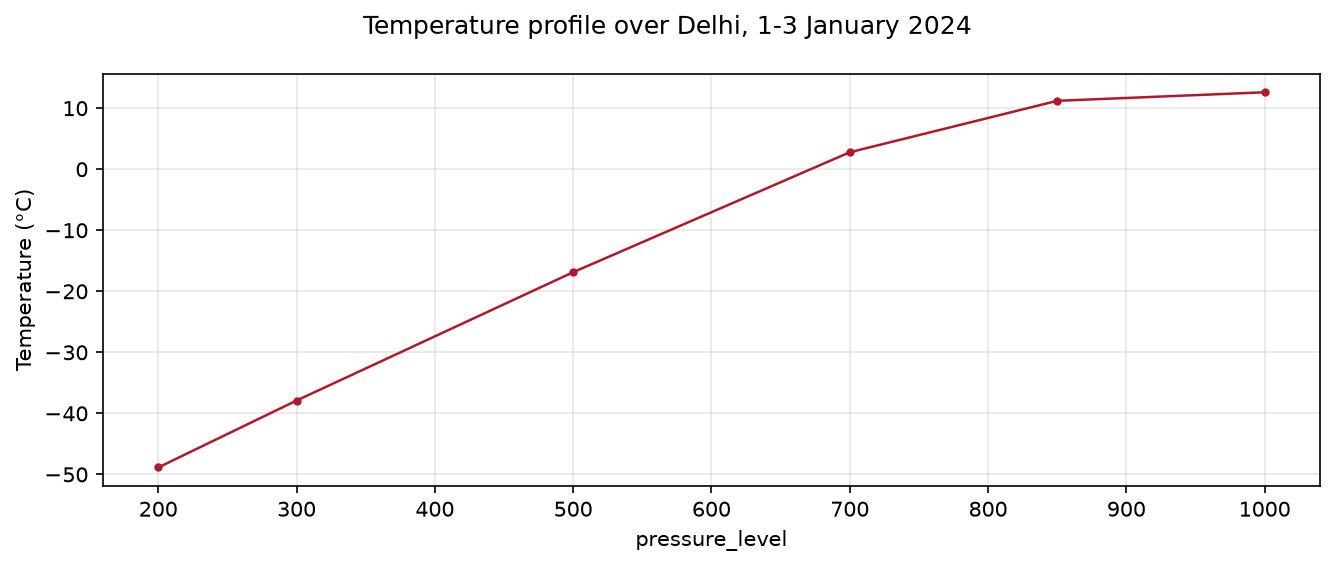

In [6]:
v.plot_series(
    v.spatial_mean(profile, "value", by="pressure_level"),
    x="pressure_level",
    y="value",
    ylabel="Temperature (°C)",
    title="Temperature profile over Delhi, 1-3 January 2024",
)

## Find a variable

ERA5 has hundreds of variables. `search_variable` finds the variables that match a word, in the single-level and pressure-level datasets.

In [7]:
v.search_variable("temperature", dataset_type="all")


=== SEARCH RESULTS (ALL LEVELS) ===
Pattern: 'temperature'
Variables found: 21

--- Temperature And Pressure ---
1. 2m_dewpoint_temperature (from single levels)
   Description: Dew point temperature at 2 meters above the surface, representing the temperature at which air becomes saturated with moisture. Unit: Kelvin (K).

2. 2m_temperature (from single levels)
   Description: Air temperature at 2 meters above the surface, typically used to represent surface-level weather conditions. Unit: Kelvin (K).

3. ice_temperature_layer_1 (from single levels)
   Description: Temperature of the top layer of sea ice. This layer is most affected by atmospheric conditions. Unit: Kelvin (K).

4. ice_temperature_layer_2 (from single levels)
   Description: Temperature of the second layer of sea ice, representing deeper internal ice temperatures. Unit: Kelvin (K).

5. ice_temperature_layer_3 (from single levels)
   Description: Temperature of the third layer of sea ice, indicating mid-level internal ic

## Describe variables

`describe_variables` gives a description and the unit of each variable. The catalog gives the original ERA5 units (K, m, Pa). The download functions convert temperature to °C and precipitation to mm.

In [8]:
v.describe_variables(
    ["2m_temperature", "total_precipitation", "surface_pressure"],
    dataset_type="single",
);


=== Variable Descriptions (SINGLE LEVELS) ===

2m_temperature:
  Category: temperature_and_pressure
  Description: Air temperature at 2 meters above the surface, typically used to represent surface-level weather conditions. Unit: Kelvin (K).

total_precipitation:
  Category: precipitation_variables
  Description: Cumulative precipitation (convective + large-scale). Unit: meters (m) of water equivalent.

surface_pressure:
  Category: temperature_and_pressure
  Description: Atmospheric pressure at the surface of the Earth. Influenced by elevation and weather systems. Unit: Pascal (Pa).
